# Replication of System A

In [1]:
using CSV, DataFrames, Plots
using Chakra, Melch
include("src/Idyoms.jl")
using Main.Idyoms

In [2]:
Melch.__INIT__("/Users/eliasdevos/Desktop/Bachelor's Thesis/MelchData") 

In [20]:
nova = fnd(Melch.id(1),Melch)
nova.description

"Chorale melodies harmonised by J."

In [ ]:
melodies = pts(nova)

#pitches_set = vcat([Melch.melody_to_df(m) for m in melodies]...);



pitches_set = geta(Melch.CPITCH, fnd(melodies[1],Melch) )


print(pitches_set)


sequences = [sequence(pts(mel,Melch),Melch) for mel in melodies];







Chakra.None()

In [12]:
PITCH = vp(Melch.CPITCH);

In [13]:
# For each sequence in the dataset, we construct a View from a source viewpoint and a target viewpoint.
# In this case, both source and target viewpoints are the same: PITCH.

pitch_view = [Main.Idyoms.View(seq,PITCH,PITCH) for seq in sequences];

In [ ]:
# the alphabet of the viewpoint PITCH.
a = pitches_set

# the type smoothing method to be used.
b = Main.Idyoms.Interpolated()

# the escape method: A(), B(), C(), D(), or X()
e = Main.Idyoms.A()

# update exclusion: true means update exclusion is on
u = true

# the order bound: Bounded(h), where h is the max context length, or Unbounded()
o = Main.Idyoms.Bounded(5);

In [22]:
@time pitch_both_plus = Idyoms.ppm_both_plus(pitch_view,a,b,e,u,o);
Idyoms.mean_infcontent(pitch_both_plus)

  1.284345 seconds (24.56 M allocations: 2.058 GiB, 47.28% gc time)


2.3897589652012985

### Tabulate predictions

We can display the prediction sequences as data frames using the todataframe function.

In [16]:
pitch_table = Idyoms.todataframe(pitch_both_plus)

Row,SeqID,EventID,Symbol,Order,Prob,IC,H
,Int64,Int64,Int64,Int64,Float64,Float64,Float64
1,1,1,73,0,0.0419511,4.57515,4.26446
2,1,2,73,1,0.32166,1.63639,3.17794
3,1,3,74,2,0.215404,2.21489,3.19156
4,1,4,76,3,0.239452,2.06219,2.45907
5,1,5,73,3,0.20977,2.25312,2.58073
6,1,6,69,2,0.0122421,6.352,2.2584
7,1,7,71,2,0.128162,2.96396,2.99654
8,1,8,73,3,0.454666,1.13712,2.54788
9,1,9,74,4,0.440065,1.18421,2.16106


### Plot information profiles

We can plot the probability, information content and entropy of a sequence using Julia's Plots library. Features in these information profiles can be used to detect structure in the sequences. 

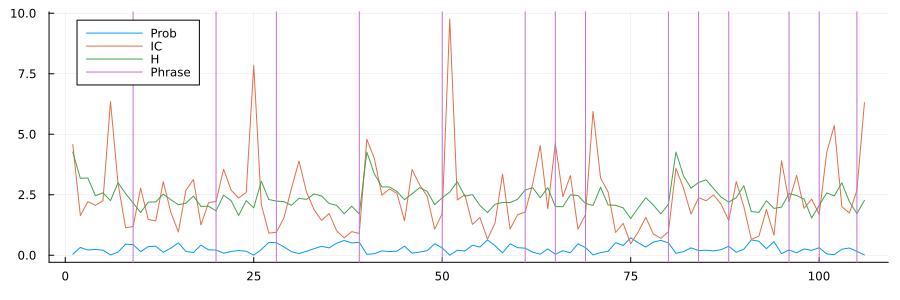

In [10]:
plot(pitch_table.Prob[1:106],label="Prob")
plot!(pitch_table.IC[1:106],label="IC")
plot!(pitch_table.H[1:106],label="H")
phrases = [e.PHRASE for e in vcat(sequences...)];
vline!(findall(x->x==-1,phrases[1:106]), lw = 1, label="Phrase")
plot!(size=(900,300))